# Prétraitement des données scRNA-seq (pancréas), sans fuite d'information


## 1. Imports et paramètres

In [1]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import scanpy as sc
from sklearn.model_selection import train_test_split

SEED = 0             # graine : même découpage à chaque exécution
N_HVG = 2000         # nombre de gènes variables conservés (à justifier et à tester)
TEST_SIZE = 0.2      # part de cellules mise en validation
DATA_DIR = "Data"    

np.random.seed(SEED)
repertoire = os.getcwd()


## 2. Chargement des données


```

In [2]:
chemin = f"{repertoire}/data/dataset.h5ad"

adata = sc.read_h5ad(chemin)
print(adata)

AnnData object with n_obs × n_vars = 16382 × 18771
    obs: 'tech', 'celltype', 'size_factors', 'n_counts', 'cell_type', 'batch'
    var: 'n_cells', 'feature_name', 'hvg', 'hvg_score'
    uns: '_from_cache', 'data_reference', 'data_url', 'dataset_description', 'dataset_id', 'dataset_name', 'dataset_organism', 'dataset_reference', 'dataset_summary', 'dataset_url', 'knn', 'normalization_id', 'pca_variance', 'var_names_all'
    obsm: 'X_pca'
    varm: 'pca_loadings'
    obsp: 'knn_connectivities', 'knn_distances'
    layers: 'counts', 'log_normalized', 'normalized'


## 3. Comptages bruts dans `adata.X`

Dans ce fichier `adata.X` est vide (`None`) : les données sont dans les layers. On repart des **comptages bruts** (`counts`) pour faire nous-mêmes la normalisation, après le découpage.

In [3]:
print("X avant :", type(adata.X))
adata.X = adata.layers["counts"].copy()
print("X après :", type(adata.X), adata.X.shape)

X avant : <class 'NoneType'>
X après : <class 'scipy.sparse._csr.csr_matrix'> (16382, 18771)


In [13]:
print(adata.var['feature_name'])



A1BG        A1BG
A1CF        A1CF
A2M          A2M
A2ML1      A2ML1
A4GALT    A4GALT
           ...  
ZXDC        ZXDC
ZYG11B    ZYG11B
ZYX          ZYX
ZZEF1      ZZEF1
ZZZ3        ZZZ3
Name: feature_name, Length: 18771, dtype: str


## 4. Suppression des résultats pré-calculés

Le fichier contient déjà une PCA, un graphe de voisins, des gènes variables (`hvg`) et des layers normalisées. Tout cela a été calculé sur **toutes** les cellules : le garder reviendrait à laisser la validation influencer le train. On le supprime et on recalcule ce dont on a besoin.

## 5. Contrôle qualité

On regarde le nombre de gènes détectés et le total de comptages par cellule, pour justifier le seuil du filtre.

       n_genes_by_counts  total_counts
count       16382.000000  1.638200e+04
mean         3396.667074  1.626118e+05
std          2032.698295  3.638252e+05
min           755.000000  1.185000e+03
25%          1780.000000  4.741087e+03
50%          2654.000000  8.548924e+03
75%          4838.750000  1.123730e+05
max         11245.000000  5.068353e+06


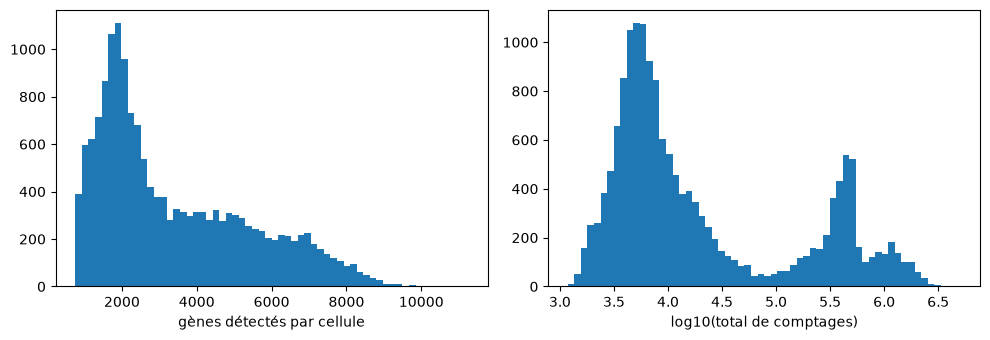

In [4]:
sc.pp.calculate_qc_metrics(adata, inplace=True)
print(adata.obs[["n_genes_by_counts", "total_counts"]].describe())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(adata.obs["n_genes_by_counts"], bins=60)
ax[0].set_xlabel("gènes détectés par cellule")
ax[1].hist(np.log10(adata.obs["total_counts"]), bins=60)
ax[1].set_xlabel("log10(total de comptages)")
plt.tight_layout()
plt.show()

## 6. Filtre des cellules

On retire les cellules avec moins de 200 gènes détectés (cellules de mauvaise qualité). Ce critère ne dépend que de chaque cellule : on peut le faire avant le découpage sans fuite.

In [5]:
n0 = adata.n_obs
sc.pp.filter_cells(adata, min_genes=200)
print(f"{n0 - adata.n_obs} cellules retirées, {adata.n_obs} restantes")

0 cellules retirées, 16382 restantes


## 7. Séparation train / validation

On sépare les **indices des cellules** avec `train_test_split`, en gardant les proportions de types cellulaires (`stratify`), puis on crée deux objets AnnData distincts. C'est l'étape clé : tout ce qui suit estime ses paramètres sur le train.

In [22]:
idx = np.arange(adata.n_obs)

effectifs = adata.obs["celltype"].value_counts()
stratif = adata.obs["celltype"] if effectifs.min() >= 2 else None
if stratif is None:
    print("Un type cellulaire n'a qu'une cellule : pas de stratification")

idx_train, idx_val = train_test_split(
    idx, test_size=TEST_SIZE, random_state=SEED, stratify=stratif
)

adata_train = adata[idx_train].copy()
adata_val = adata[idx_val].copy()

print("train :", adata_train.shape)
print("val   :", adata_val.shape)

# proportions des types cellulaires dans chaque jeu
prop = pd.concat(
    [adata_train.obs["celltype"].value_counts(normalize=True).rename("train"),
     adata_val.obs["celltype"].value_counts(normalize=True).rename("val")],
    
    axis=1,
)
print(prop.round(3))

train : (13105, 18771)
val   : (3277, 18771)
                    train    val
celltype                        
alpha               0.335  0.335
beta                0.254  0.255
ductal              0.131  0.131
acinar              0.102  0.102
delta               0.064  0.064
gamma               0.043  0.043
activated_stellate  0.028  0.028
endothelial         0.019  0.019
quiescent_stellate  0.012  0.012
macrophage          0.005  0.005
mast                0.003  0.002
epsilon             0.002  0.002
schwann             0.002  0.002
t_cell              0.000  0.000


## 8. Filtre des gènes

On retire les gènes détectés dans moins de 3 cellules **du train**, puis on garde les mêmes gènes dans la validation.

In [7]:
n_genes_avant = adata_train.n_vars
sc.pp.filter_genes(adata_train, min_cells=3)
adata_val = adata_val[:, adata_train.var_names].copy()
print(f"{n_genes_avant - adata_train.n_vars} gènes retirés, {adata_train.n_vars} restants")

615 gènes retirés, 18156 restants


## 9. Normalisation puis `log1p`

- **Normalisation** (`normalize_total`) : chaque cellule est ramenée à 10 000 comptages au total (CP10k), pour que la profondeur de séquençage ne fausse pas les comparaisons entre cellules.
- **`log1p`** : compresse l'échelle, car quelques gènes très exprimés (insuline...) écraseraient les autres. Le « +1 » évite log(0).
- On fixe `target_sum=1e4` : train et validation sont normalisés vers la même valeur (sinon chaque jeu utiliserait sa propre médiane).

In [8]:
for a in (adata_train, adata_val):
    sc.pp.normalize_total(a, target_sum=1e4)
    sc.pp.log1p(a)

X = adata_train.X
X = X.expm1() if sp.issparse(X) else np.expm1(X)
print(np.asarray(X.sum(axis=1)).ravel()[:5])


[10000.    10000.    10000.    10000.001 10000.   ]


## 10. Gènes hautement variables (HVG)



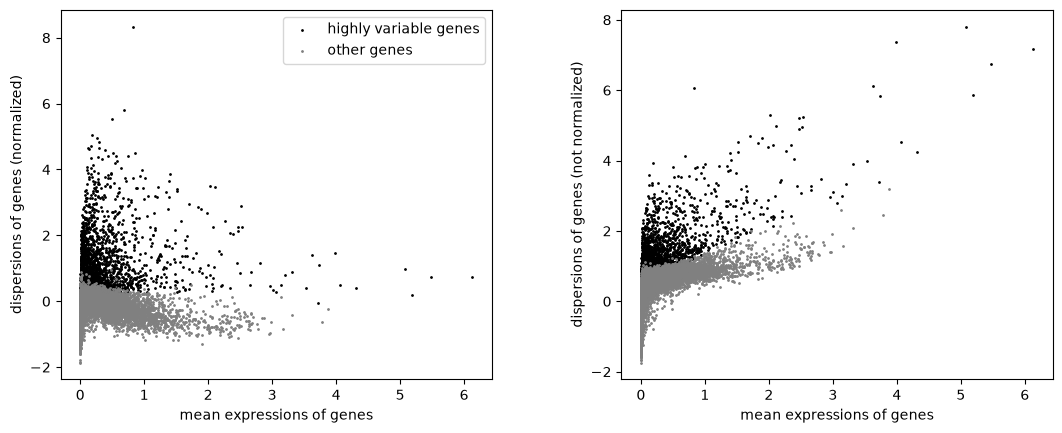

3000 gènes variables retenus


In [9]:
sc.pp.highly_variable_genes(adata_train, n_top_genes=3000, batch_key = 'batch')
sc.pl.highly_variable_genes(adata_train)

genes = adata_train.var_names[adata_train.var["highly_variable"]]
print(len(genes), "gènes variables retenus")

adata_train = adata_train[:, genes].copy()
adata_val = adata_val[:, genes].copy()

Min: 0.000, Max: 8.915, Moyenne: 0.155
Proportion de zéros: 84.90%


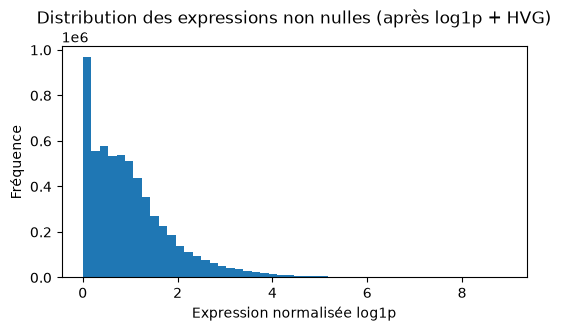

In [10]:
import numpy as np
import matplotlib.pyplot as plt

X = adata_train.X.toarray() if hasattr(adata_train.X, "toarray") else adata_train.X

print(f"Min: {X.min():.3f}, Max: {X.max():.3f}, Moyenne: {X.mean():.3f}")
print(f"Proportion de zéros: {(X == 0).mean():.2%}")

plt.figure(figsize=(6, 3))
plt.hist(X[X > 0].flatten(), bins=50)
plt.title("Distribution des expressions non nulles (après log1p + HVG)")
plt.xlabel("Expression normalisée log1p")
plt.ylabel("Fréquence")
plt.show()

## 12. Sauvegarde



In [11]:
adata_train.write_h5ad(f"{repertoire}/data/train.h5ad")
adata_val.write_h5ad(f"{repertoire}/data/val.h5ad")

